# **Project: Customer Sentiment Prediction and Personalized Experience Engine for Airlines**

# **Data Collection and Sentiment Analysis**

In [2]:
# Importing basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Mounting google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Loading raw csv file
file_path = '/content/drive/MyDrive/Colab Notebooks/british_airways_reviews1.csv'
df = pd.read_csv(file_path)

In [4]:
# Displaying the first few rows of the dataframe
print(df.head(2))

   Unnamed: 0                                     title  \
0           0  "unprofessional attitude of the pilots"    
1           1               “Next time it will be Jet2”   

                                             reviews  
0    BA 246 21JAN 2023 Did not appreciate the unp...  
1   Not a great experience. I could not check in ...  


In [3]:
# Removing unnamed column and keep required columns
df = df.loc[:, ~df.columns.str.contains('^Unnamed')]
df.head(2)

,title,reviews
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101 entries, 0 to 100
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   title    101 non-null    object
 1   reviews  101 non-null    object
dtypes: object(2)
memory usage: 1.7+ KB


Now we have some cleaned dataset, we need to go further process such as tokenization, lemmitization and removing stop words, etc.

**Text cleaning and Tokenization**

Before executing this we need install few libraries as it suggested while running.

For this process we need to import NLTK (Natural Language Took Kit) and its libraries as per requirement

In [4]:
import nltk
#Downloasing punkt and stopwords
nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [5]:
# importing supporting libraries
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [6]:
#Text cleaning and Tokenization
import re
import string
import unicodedata

URL_RE = re.compile(r"https?://\S+|www\.\S+")
HTML_RE = re.compile(r"<.*?>")
MENTION_RE = re.compile(r"[@#]\w+")
PUNCT_TABLE = str.maketrans("", "", string.punctuation)
stop_words = set(stopwords.words("english"))

def clean_text(text: str) -> str:
    text = str(text).lower()
    text = URL_RE.sub(" ", text)
    text = HTML_RE.sub(" ", text)
    text = MENTION_RE.sub(" ", text)
    text = unicodedata.normalize("NFKC", text)
    text = text.translate(PUNCT_TABLE)
    text = re.sub(r"\d+", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

def remove_stop_tokens(text: str) -> str:
    toks = word_tokenize(text)
    toks = [t for t in toks if t not in stop_words and len(t) > 1]
    return " ".join(toks)

df["clean_review"] = df["reviews"].apply(clean_text)
df["processed_review"] = df["clean_review"].apply(remove_stop_tokens)
df.head()

,title,reviews,clean_review,processed_review
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan did not appreciate the unprofessional a...,ba jan appreciate unprofessional attitude pilo...
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not a great experience i could not check in on...,great experience could check online two separa...
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,i was excited to fly ba as id not travelled wi...,excited fly ba id travelled long haul yrs ive ...
3,“They never help us”,I just want to warn everyone of the worst cu...,i just want to warn everyone of the worst cust...,want warn everyone worst customer service expe...
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid for business class travelling cairo to lo...,paid business class travelling cairo london he...


Additinally we added two more columns such as clean_review and processed review

We need to import spacy library to lemmatize

In [7]:
import spacy
# spaCy for lemmatization
nlp = spacy.load("en_core_web_sm", disable=["ner","parser"])

In [8]:
#Lemmatization
def lemmatize(text: str) -> str:
    doc = nlp(text)
    out = []
    for t in doc:
        if t.is_space:
            continue
        lemma = t.lemma_.strip()
        if not lemma:
            continue
        # filter tiny tokens & stopwords
        if len(lemma) < 2 or lemma in stop_words:
            continue
        out.append(lemma)
    return " ".join(out)

df["lemma_review"] = df["clean_review"].apply(lemmatize)
df.head()

,title,reviews,clean_review,processed_review,lemma_review
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan did not appreciate the unprofessional a...,ba jan appreciate unprofessional attitude pilo...,ba jan appreciate unprofessional attitude pilo...
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not a great experience i could not check in on...,great experience could check online two separa...,great experience could check online two separa...
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,i was excited to fly ba as id not travelled wi...,excited fly ba id travelled long haul yrs ive ...,excited fly ba travel long haul yrs travel aus...
3,“They never help us”,I just want to warn everyone of the worst cu...,i just want to warn everyone of the worst cust...,want warn everyone worst customer service expe...,want warn everyone bad customer service experi...
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid for business class travelling cairo to lo...,paid business class travelling cairo london he...,pay business class travel cairo london heathro...


Now we added lemma rivew also to dataset

## **Performing Sentiment analysis using VADER, TextBlob and BERT Models**

1. Performing Sentiment analysis by VADER model

In [9]:
# Downloading vader lexicon library
nltk.download("vader_lexicon", quiet=True)

True

In [10]:
# Creating object
from nltk.sentiment import SentimentIntensityAnalyzer
vader = SentimentIntensityAnalyzer()

In [11]:
# Extracting polarity scores for one random review for checking
row = df.sample(1).iloc[0]
print(row["clean_review"])
print(vader.polarity_scores(row["clean_review"]))
print(row["processed_review"])
print(vader.polarity_scores(row["processed_review"]))
print(row["lemma_review"])
print(vader.polarity_scores(row["lemma_review"]))

boarded on time but it took ages to get to the runway due to congestion flight was smooth and quick snack and drinks were good for a short flight landed only about ten minutes late one bag of three left in london forms quickly filled in and the bag was delivered the next morning
{'neg': 0.0, 'neu': 0.931, 'pos': 0.069, 'compound': 0.5927}
boarded time took ages get runway due congestion flight smooth quick snack drinks good short flight landed ten minutes late one bag three left london forms quickly filled bag delivered next morning
{'neg': 0.0, 'neu': 0.914, 'pos': 0.086, 'compound': 0.4404}
board time take age get runway due congestion flight smooth quick snack drink good short flight land ten minute late one bag three leave london form quickly fill bag deliver next morning
{'neg': 0.035, 'neu': 0.88, 'pos': 0.085, 'compound': 0.4019}


I checked polarity scores for few samples and observed some insights mentioned below, which I ran in VADER results.
 - clean_review works on exact words, where stopwords are not removed, so showing some inconsistency.
 - processed_review worked on removed stop words such the, is etc., which adds more weight.
 - lemma_review changed words into past to present and plural to singular etc.

At end there is no drastic change found in processed_review and lemma_review. So I am opting **Lemma_review** scores for further analysis.



In [12]:
# Creating two columns such as Sentiment score and its mapping
v_score = pd.DataFrame()

def vader_label(text: str) -> str:
    s = vader.polarity_scores(text)["compound"]
    if s >= 0.2: return "pos",s
    if s <= -0.2: return "neg",s
    return "neu",s

v_score[["sent_vader","score_vader"]] = df["lemma_review"].apply(vader_label).apply(pd.Series)
v_score.head(2)

,sent_vader,score_vader
0,pos,0.2960
1,pos,0.9325


In [13]:
v_score['sent_vader'].value_counts()

,count
sent_vader,
pos,49
neg,45
neu,7


2. Performing Sentiment analysis by TextBlob model

In [14]:
from textblob import TextBlob

In [15]:
# Extracting polarity scores for one random review for checking
row = df.sample(1).iloc[0]
print(row["clean_review"])
print(TextBlob(row["clean_review"]).sentiment.polarity)
print(row["processed_review"])
print(TextBlob(row["processed_review"]).sentiment.polarity)
print(row["lemma_review"])
print(TextBlob(row["lemma_review"]).sentiment.polarity)

my initial flight was cancelled hours prior the flight then i was automatically rescheduled for next day next day the flight was delayed leaving hamburg and missed my connecting flight to las vegas me and several other passengers spent the night in london british airways provided us with vouchers but the transfer bus dropped us at the wrong hotel closest to our hotel and told us that we can walk there if we want to as a result i lost two nights hotel reservations that i made in las vegas i opened a claim and provided all receipts to british airways to get refund of my hotel reservations but over weeks now not a single feedback from british airways i will avoid all flights with them in future and will share this story
-0.05302197802197802
initial flight cancelled hours prior flight automatically rescheduled next day next day flight delayed leaving hamburg missed connecting flight las vegas several passengers spent night london british airways provided us vouchers transfer bus dropped us

Found there is huge difference between those 3 reviews. I go with lemma review only for further analysis

In [16]:
# Creating two columns such as Sentiment score and its mapping
tb_score = pd.DataFrame()

def textblob_label(text: str) -> str:
    p = TextBlob(text).sentiment.polarity
    if p > 0.05: return "pos",p
    if p < -0.05: return "neg",p
    return "neu",p

tb_score[["sent_tb","score_tb"]] = df["lemma_review"].apply(textblob_label).apply(pd.Series)
tb_score.head(2)

,sent_tb,score_tb
0,pos,0.062500
1,pos,0.173165


In [17]:
tb_score['sent_tb'].value_counts()

,count
sent_tb,
pos,47
neg,27
neu,27


3. Performing Sentiment analysis by BERT model

In [18]:
# Importing pipeline
from transformers import pipeline

In [19]:
from tqdm import tqdm
tqdm.pandas()

In [20]:
# object creation for pipeline
bert_pipe = pipeline("sentiment-analysis", model="cardiffnlp/twitter-roberta-base-sentiment-latest")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/501M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/501M [00:00<?, ?B/s]

Some weights of the model checkpoint at cardiffnlp/twitter-roberta-base-sentiment-latest were not used when initializing RobertaForSequenceClassification: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing RobertaForSequenceClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Device set to use cpu


In [21]:
# Creating data frame for BERT model
texts = df["lemma_review"].tolist()
bert_dict_list= []
for i in tqdm(range(0, len(texts)), desc="BERT sentiment"):
    chunk = texts[i]
    outs = bert_pipe(chunk)
    bert_dict_list.append(outs[0])
bert_score = pd.DataFrame(bert_dict_list)
bert_score.head()

BERT sentiment: 100%|██████████| 101/101 [01:03<00:00,  1.59it/s]


,label,score
0,negative,0.807338
1,positive,0.734100
2,negative,0.475450
3,negative,0.706292
4,negative,0.912401


In [22]:
# Renaming the columns and mapping
bert_score.rename(columns={"label":"sent_bert", "score":"score_bert"}, inplace=True)
bert_score["sent_bert"] = bert_score["sent_bert"].map({"negative":"neg", "neutral":"neu", "positive":"pos"})
bert_score.head()

,sent_bert,score_bert
0,neg,0.807338
1,pos,0.734100
2,neg,0.475450
3,neg,0.706292
4,neg,0.912401


In [23]:
bert_score['sent_bert'].value_counts()

,count
sent_bert,
neg,56
pos,23
neu,22


In [24]:
# Merging above 3 models to main data frame
df_merge = pd.concat([df, v_score, tb_score, bert_score], axis=1)
print(df_merge.columns)
print(df_merge.head(2))

Index(['title', 'reviews', 'clean_review', 'processed_review', 'lemma_review',
       'sent_vader', 'score_vader', 'sent_tb', 'score_tb', 'sent_bert',
       'score_bert'],
      dtype='object')
                                      title  \
0  "unprofessional attitude of the pilots"    
1               “Next time it will be Jet2”   

                                             reviews  \
0    BA 246 21JAN 2023 Did not appreciate the unp...   
1   Not a great experience. I could not check in ...   

                                        clean_review  \
0  ba jan did not appreciate the unprofessional a...   
1  not a great experience i could not check in on...   

                                    processed_review  \
0  ba jan appreciate unprofessional attitude pilo...   
1  great experience could check online two separa...   

                                        lemma_review sent_vader  score_vader  \
0  ba jan appreciate unprofessional attitude pilo...        pos       0.2960

In [28]:
output_file_path = '/content/drive/MyDrive/Colab Notebooks/british_airways_processed_reviews.csv'
df_merge.to_csv(output_file_path, index=False)
print(f"DataFrame exported successfully to {output_file_path}")

DataFrame exported successfully to /content/drive/MyDrive/Colab Notebooks/british_airways_processed_reviews.csv


# **Customer Satisfaction Prediction Model**

In [3]:
# Loading Processed review data set
file_path1 = '/content/drive/MyDrive/Colab Notebooks/british_airways_processed_reviews.csv'
df1 = pd.read_csv(file_path1)
df1.head()

,title,reviews,clean_review,processed_review,lemma_review,sent_vader,score_vader,sent_tb,score_tb,sent_bert,score_bert
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan did not appreciate the unprofessional a...,ba jan appreciate unprofessional attitude pilo...,ba jan appreciate unprofessional attitude pilo...,pos,0.2960,pos,0.062500,neg,0.807338
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not a great experience i could not check in on...,great experience could check online two separa...,great experience could check online two separa...,pos,0.9325,pos,0.173165,pos,0.734100
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,i was excited to fly ba as id not travelled wi...,excited fly ba id travelled long haul yrs ive ...,excited fly ba travel long haul yrs travel aus...,pos,0.6908,pos,0.122083,neg,0.475450
3,“They never help us”,I just want to warn everyone of the worst cu...,i just want to warn everyone of the worst cust...,want warn everyone worst customer service expe...,want warn everyone bad customer service experi...,pos,0.8548,pos,0.076812,neg,0.706292
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid for business class travelling cairo to lo...,paid business class travelling cairo london he...,pay business class travel cairo london heathro...,neg,-0.8080,neg,-0.560000,neg,0.912401


In [26]:
df1.describe()

,score_vader,score_tb,score_bert
count,101.000000,101.000000,101.000000
mean,0.050907,0.032823,0.754066
std,0.762869,0.188033,0.145583
min,-0.982600,-0.600000,0.400183
25%,-0.778000,-0.055291,0.665219
50%,0.153100,0.036275,0.789192
75%,0.859100,0.136029,0.870714
max,0.994000,0.454048,0.976650


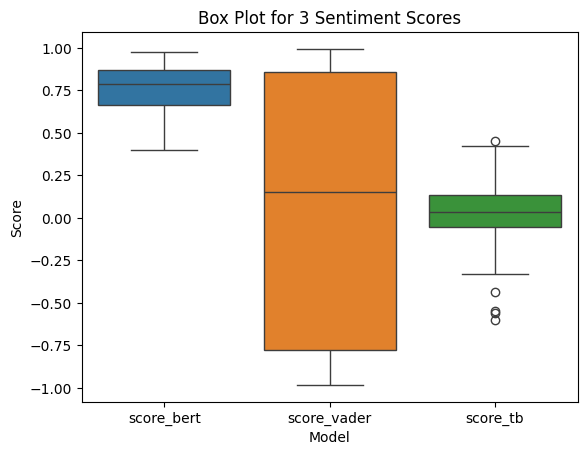

In [27]:
sns.boxplot(data=df1[["score_bert","score_vader","score_tb"]])
plt.title("Box Plot for 3 Sentiment Scores")
plt.xlabel("Model")
plt.ylabel("Score")
plt.show()

By this box plot there is a little desrepancy. So need to normalize those values.

In [4]:
# Normalizing for sentiment scores
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df1[["score_bert_norm", "score_vader_norm", "score_tb_norm"]] = scaler.fit_transform(
    df1[["score_bert", "score_vader", "score_tb"]]
)
df1.head()

,title,reviews,clean_review,processed_review,lemma_review,sent_vader,score_vader,sent_tb,score_tb,sent_bert,score_bert,score_bert_norm,score_vader_norm,score_tb_norm
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan did not appreciate the unprofessional a...,ba jan appreciate unprofessional attitude pilo...,ba jan appreciate unprofessional attitude pilo...,pos,0.2960,pos,0.062500,neg,0.807338,0.706294,0.646868,0.628529
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not a great experience i could not check in on...,great experience could check online two separa...,great experience could check online two separa...,pos,0.9325,pos,0.173165,pos,0.734100,0.579247,0.968886,0.733520
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,i was excited to fly ba as id not travelled wi...,excited fly ba id travelled long haul yrs ive ...,excited fly ba travel long haul yrs travel aus...,pos,0.6908,pos,0.122083,neg,0.475450,0.130567,0.846605,0.685058
3,“They never help us”,I just want to warn everyone of the worst cu...,i just want to warn everyone of the worst cust...,want warn everyone worst customer service expe...,want warn everyone bad customer service experi...,pos,0.8548,pos,0.076812,neg,0.706292,0.531010,0.929576,0.642107
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid for business class travelling cairo to lo...,paid business class travelling cairo london he...,pay business class travel cairo london heathro...,neg,-0.8080,neg,-0.560000,neg,0.912401,0.888548,0.088334,0.037949


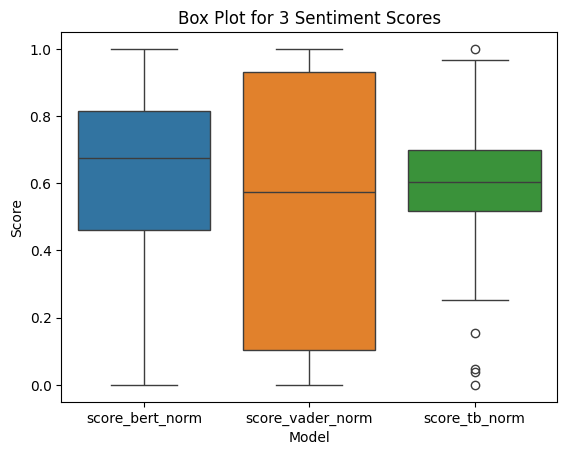

In [29]:
# Box plot again
sns.boxplot(data=df1[["score_bert_norm", "score_vader_norm", "score_tb_norm"]])
plt.title("Box Plot for 3 Sentiment Scores")
plt.xlabel("Model")
plt.ylabel("Score")
plt.show()

As per above box plot all scores are normalized and followed different ranges to determine sentiment.
Now with the use of all these scores i will generate csat score.

In [5]:
# creating new data frame by considering required columns
df2 = df1[["lemma_review","score_bert_norm", "score_vader_norm", "score_tb_norm"]]
df2.head()

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm
0,ba jan appreciate unprofessional attitude pilo...,0.706294,0.646868,0.628529
1,great experience could check online two separa...,0.579247,0.968886,0.733520
2,excited fly ba travel long haul yrs travel aus...,0.130567,0.846605,0.685058
3,want warn everyone bad customer service experi...,0.531010,0.929576,0.642107
4,pay business class travel cairo london heathro...,0.888548,0.088334,0.037949


Due to unavailability of CSAT labels, calculated ensemble scores by adding weights to normalized sentiment scores. Here We gave more weight to Bert model as it is developed by deep learning and followed by vader and textblob given less weight as of inconsistencies.

In [6]:
# Creating single sentiment signal by weighted average method
df2["ensemble_score"] = (
    0.5 * df2["score_bert_norm"] +
    0.3 * df2["score_vader_norm"] +
    0.2 * df2["score_tb_norm"]
)
df2.head()

/tmp/ipython-input-938891987.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["ensemble_score"] = (


,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score
0,ba jan appreciate unprofessional attitude pilo...,0.706294,0.646868,0.628529,0.672913
1,great experience could check online two separa...,0.579247,0.968886,0.733520,0.726993
2,excited fly ba travel long haul yrs travel aus...,0.130567,0.846605,0.685058,0.456277
3,want warn everyone bad customer service experi...,0.531010,0.929576,0.642107,0.672799
4,pay business class travel cairo london heathro...,0.888548,0.088334,0.037949,0.478364


In [7]:
# Converting ensemble scores to csat labels
df2["csat_label"] = pd.cut(
    df2["ensemble_score"],
    bins=[0, 0.4, 0.65, 1.0],
    labels=["Low", "Neutral", "High"]
)
df2.head()

/tmp/ipython-input-3736013420.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["csat_label"] = pd.cut(


,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label
0,ba jan appreciate unprofessional attitude pilo...,0.706294,0.646868,0.628529,0.672913,High
1,great experience could check online two separa...,0.579247,0.968886,0.733520,0.726993,High
2,excited fly ba travel long haul yrs travel aus...,0.130567,0.846605,0.685058,0.456277,Neutral
3,want warn everyone bad customer service experi...,0.531010,0.929576,0.642107,0.672799,High
4,pay business class travel cairo london heathro...,0.888548,0.088334,0.037949,0.478364,Neutral


<Axes: xlabel='csat_label'>

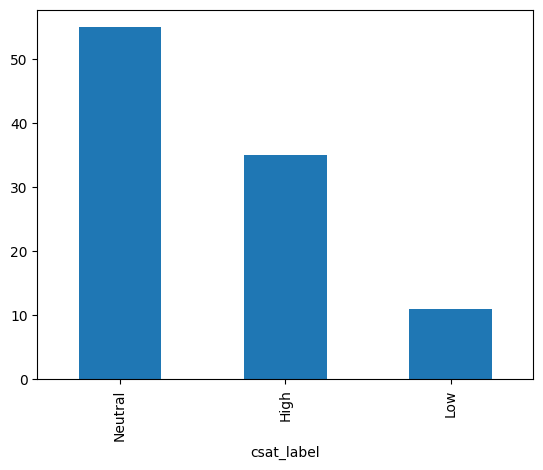

In [33]:
# Bar plot for csat_label
df2["csat_label"].value_counts().plot(kind="bar")

In [8]:
# Encoding csat lable
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df2["csat_enc"] = le.fit_transform(df2["csat_label"])
df2.head()

/tmp/ipython-input-3539056323.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2["csat_enc"] = le.fit_transform(df2["csat_label"])


,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc
0,ba jan appreciate unprofessional attitude pilo...,0.706294,0.646868,0.628529,0.672913,High,0
1,great experience could check online two separa...,0.579247,0.968886,0.733520,0.726993,High,0
2,excited fly ba travel long haul yrs travel aus...,0.130567,0.846605,0.685058,0.456277,Neutral,2
3,want warn everyone bad customer service experi...,0.531010,0.929576,0.642107,0.672799,High,0
4,pay business class travel cairo london heathro...,0.888548,0.088334,0.037949,0.478364,Neutral,2


In [10]:
# Splitting the data into features and pediction
X = df2[["score_bert_norm", "score_vader_norm", "score_tb_norm"]]
y = df2["csat_enc"]

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


Training the model and Evaluation in Random Forest Classifier

In [12]:
# Training the model in Random Forest classifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report

model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

# Evaluation model with Test set
y_pred = model.predict(X_test)

#print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.86      0.92         7
           1       1.00      0.50      0.67         2
           2       0.86      1.00      0.92        12

    accuracy                           0.90        21
   macro avg       0.95      0.79      0.84        21
weighted avg       0.92      0.90      0.90        21



In [40]:
y_pred

array([2, 0, 2, 2, 2, 2, 2, 2, 0, 0, 0, 0, 2, 2, 0, 2, 2, 2, 1, 2, 2])

In [41]:
X_test

,score_bert_norm,score_vader_norm,score_tb_norm
36,0.632762,0.008550,0.610099
37,0.904668,0.993221,0.967698
72,0.394370,0.939998,0.600625
49,0.451823,0.819336,0.492892
4,0.888548,0.088334,0.037949
57,0.788970,0.200698,0.575164
69,0.219233,0.370636,0.538329
26,0.865361,0.027269,0.553573
18,0.944221,0.987554,0.833296
64,0.674816,0.737478,0.623259


In [13]:
import joblib

joblib.dump(model, "rf_model.pkl")


['rf_model.pkl']

In [14]:
loaded_model = joblib.load("rf_model.pkl")
loaded_model.feature_importances_

array([0.30300958, 0.40122832, 0.2957621 ])

According to above metrics
- Got accuracy of 90% as predictions are good.
- As recall of 79% shows at macro average indicates uneven class performance and it highlights low csat detection.
- Other hand weighted average shows recall of 90%, it reflects real distribution and it is best indicator of current model performance.

Training the model and Evaluation in Logistic Regression

In [15]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print(classification_report(y_test, y_pred_lr, target_names=le.classes_))

Accuracy: 0.7619047619047619
              precision    recall  f1-score   support

        High       0.75      0.86      0.80         7
         Low       0.00      0.00      0.00         2
     Neutral       0.77      0.83      0.80        12

    accuracy                           0.76        21
   macro avg       0.51      0.56      0.53        21
weighted avg       0.69      0.76      0.72        21



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [16]:
joblib.dump(lr, "lr_model.pkl")

['lr_model.pkl']

In [53]:
lr_model = joblib.load("lr_model.pkl")
print(lr_model.coef_)

[[ 1.75509016  2.54215119  1.07093527]
 [-2.0540087  -1.7512594  -0.04922493]
 [ 0.29891853 -0.79089179 -1.02171034]]


Training the model and Evaluation in SVM

In [17]:
from sklearn.svm import SVC

svm = SVC(kernel='rbf', probability=True)
svm.fit(X_train, y_train)

y_pred_svm = svm.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_svm))
print(classification_report(y_test, y_pred_svm, target_names=le.classes_))


Accuracy: 0.9523809523809523
              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       1.00      1.00      1.00         2
     Neutral       0.92      1.00      0.96        12

    accuracy                           0.95        21
   macro avg       0.97      0.95      0.96        21
weighted avg       0.96      0.95      0.95        21



In [18]:
joblib.dump(svm, "svm_model.pkl")

['svm_model.pkl']

In [56]:
svm_model = joblib.load("svm_model.pkl")
print(svm_model.support_vectors_)

[[0.53100966 0.92957604 0.64210723]
 [0.60112388 0.87276131 0.6172285 ]
 [0.47243758 0.98542953 0.71436639]
 [0.69343316 0.85141151 0.60184662]
 [0.84634792 0.30395629 0.77253219]
 [0.70629391 0.64686836 0.62852948]
 [1.         0.98993221 0.74429636]
 [0.54565203 0.84761712 0.84594534]
 [0.63139906 0.88055246 0.56923424]
 [0.42797507 0.98446828 0.82376249]
 [0.86011422 0.96696347 1.        ]
 [0.54176309 0.94910452 0.68746535]
 [0.18505862 0.17368208 0.53602891]
 [0.1778277  0.09693413 0.44612604]
 [0.19814219 0.12121825 0.55377992]
 [0.537191   0.045128   0.52405692]
 [0.         0.5745725  0.77795347]
 [0.4597588  0.06804614 0.65125932]
 [0.74943719 0.29378731 0.61359016]
 [0.85116144 0.05519579 0.71357578]
 [0.38827024 0.9674188  0.67157343]
 [0.92457348 0.06612365 0.        ]
 [0.54473046 0.33689163 0.63617198]
 [0.25756978 0.91652332 0.63770047]
 [0.10872692 0.94242639 0.69828858]
 [0.2893532  0.6798543  0.88635394]
 [0.69716298 0.1033593  0.505986  ]
 [0.38567995 0.99337246 0.66

Training the model and Evaluation in KNN

In [19]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)

y_pred_knn = knn.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_knn))
print(classification_report(y_test, y_pred_knn, target_names=le.classes_))


Accuracy: 0.9523809523809523
              precision    recall  f1-score   support

        High       1.00      0.86      0.92         7
         Low       1.00      1.00      1.00         2
     Neutral       0.92      1.00      0.96        12

    accuracy                           0.95        21
   macro avg       0.97      0.95      0.96        21
weighted avg       0.96      0.95      0.95        21



In [20]:
joblib.dump(knn, "knn_model.pkl")

['knn_model.pkl']

In [59]:
knn_model = joblib.load("knn_model.pkl")
print(knn_model.kneighbors(X_test))

(array([[0.13369757, 0.15484132, 0.16334859, 0.16726712, 0.18752082],
       [0.06097479, 0.09195647, 0.11703746, 0.16790139, 0.23334059],
       [0.07630672, 0.08453315, 0.14317772, 0.1436656 , 0.14524336],
       [0.10427612, 0.12555559, 0.14756787, 0.20150624, 0.20171439],
       [0.05017093, 0.05684421, 0.22586703, 0.33781666, 0.37071041],
       [0.06107043, 0.06588599, 0.09954986, 0.10818965, 0.11462917],
       [0.19991046, 0.23245576, 0.234163  , 0.2448747 , 0.25078474],
       [0.04756994, 0.04764621, 0.0821272 , 0.08563255, 0.09503818],
       [0.03828653, 0.04980624, 0.10506121, 0.13369792, 0.14800704],
       [0.09606686, 0.11741301, 0.15133667, 0.15416978, 0.15897747],
       [0.0125384 , 0.03770399, 0.1379233 , 0.14602794, 0.14795559],
       [0.12031561, 0.12764524, 0.12975356, 0.14189758, 0.14445789],
       [0.1876064 , 0.20692499, 0.2223054 , 0.24289181, 0.28144581],
       [0.17234658, 0.19162418, 0.22120535, 0.23344907, 0.24329605],
       [0.11562714, 0.1224752 , 0

I train same data in different models. Except logistic regression, both SVM and KNN shows results and showing accuracy 95% in both of these models.

In [67]:
output_file_path = '/content/drive/MyDrive/Colab Notebooks/british_airways_with_csat.csv'
df2.to_csv(output_file_path, index=False)
print(f"DataFrame exported successfully to {output_file_path}")

DataFrame exported successfully to /content/drive/MyDrive/Colab Notebooks/british_airways_with_csat.csv


# **Summary**

- Cleaned raw text and categorized in 3 reviews such as cleaned_review, Processed_review and Lemma_review. Finally considered lemma_review for further process as it filters entire text in to crisp and noun format by removing stop words (the, is, etc.), exclamatory symbols, pull stops, etc.
- Extracted weighted scores from different models such as Vader, Textblob and BERT. Compared all three and found BERT score gives accurate prediction as it is associated with external documents and provide scores.
- Normalized all scores to 0 to 1 to avoid inconsistacies during training the models.
- Extracted CSAT scores based on combined of all three models by adding weight to preffered models on its scores. And categorized into High, Low and Neutral for CSAT score. Then encoding the label as 0 for high, 1 for low and 2 for neutral, which is essential to before training the ML model as it supports numericals.
- Splitted Training set and Test set based on 80:20 ratio for Training and Evaluating the model, where Normalized scores of 3 models as input features and CSAT scores as Target feature.
- Applied these variable to intiate training and performed on different classification models such as Random forest, SVM, KNN and Logistic Regression.
- Achieved accuracy of 90% in Random forest and 95% in SVM, KNN models.
- Achieved 100% precission on High and Low category for all 3 models, 86% in Random Forest and 92% in SVM, KNN models for neutral category.
- Recalls values depicts 100% aligned with neutral category, 86% for High class and 50% for Low class, which indicates there is inconsistency in Low scored reviews, nothing but people are deceptive at giving negative reviews.
- Got High F1 score for High and Neutral classes, then otherhand average F1 score in RF model and 100% score in SVM, KNN models. It clearly indicates Model struggling to find low rank reviews.
- Majority of support value (12) to Neutral category, while getting low support to other categories. Clearly showed that Majority of people neither fully satisfied nor fully rejected. It may indicates majority are not interested to give feedback.


# **Personalized Experience Recommendation System**

In [21]:
# Loading csat data set
path_csat = '/content/drive/MyDrive/Colab Notebooks/british_airways_with_csat.csv'
df_csat = pd.read_csv(path_csat)
df_csat.head()

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc
0,ba jan appreciate unprofessional attitude pilo...,0.706294,0.646868,0.628529,0.672913,High,0
1,great experience could check online two separa...,0.579247,0.968886,0.733520,0.726993,High,0
2,excited fly ba travel long haul yrs travel aus...,0.130567,0.846605,0.685058,0.456277,Neutral,2
3,want warn everyone bad customer service experi...,0.531010,0.929576,0.642107,0.672799,High,0
4,pay business class travel cairo london heathro...,0.888548,0.088334,0.037949,0.478364,Neutral,2


In [61]:
df_csat.columns

Index(['lemma_review', 'score_bert_norm', 'score_vader_norm', 'score_tb_norm',
       'ensemble_score', 'csat_label', 'csat_enc'],
      dtype='object')

In [62]:
# Loading Processed review data set
path_prs = '/content/drive/MyDrive/Colab Notebooks/british_airways_processed_reviews.csv'
df_prs = pd.read_csv(path_prs)
df_prs.head()

,title,reviews,clean_review,processed_review,lemma_review,sent_vader,score_vader,sent_tb,score_tb,sent_bert,score_bert
0,"""unprofessional attitude of the pilots""",BA 246 21JAN 2023 Did not appreciate the unp...,ba jan did not appreciate the unprofessional a...,ba jan appreciate unprofessional attitude pilo...,ba jan appreciate unprofessional attitude pilo...,pos,0.2960,pos,0.062500,neg,0.807338
1,“Next time it will be Jet2”,Not a great experience. I could not check in ...,not a great experience i could not check in on...,great experience could check online two separa...,great experience could check online two separa...,pos,0.9325,pos,0.173165,pos,0.734100
2,“become the Ryanair of long-haul travel”,I was excited to fly BA as I'd not travelled ...,i was excited to fly ba as id not travelled wi...,excited fly ba id travelled long haul yrs ive ...,excited fly ba travel long haul yrs travel aus...,pos,0.6908,pos,0.122083,neg,0.475450
3,“They never help us”,I just want to warn everyone of the worst cu...,i just want to warn everyone of the worst cust...,want warn everyone worst customer service expe...,want warn everyone bad customer service experi...,pos,0.8548,pos,0.076812,neg,0.706292
4,“uncomfortable seat and disgusting food”,Paid for business class travelling Cairo to L...,paid for business class travelling cairo to lo...,paid business class travelling cairo london he...,pay business class travel cairo london heathro...,neg,-0.8080,neg,-0.560000,neg,0.912401


In [22]:
# Filtering negative reviews based on csat label as low
negative_reviews = df_csat[df_csat["csat_label"] == "Low"].copy()
negative_reviews

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc
8,always fly ba total shamble book manchester lo...,0.459759,0.068046,0.651259,0.380545,Low,1
13,flight leave time arrive half hour early sched...,0.198142,0.121218,0.553780,0.246193,Low,1
22,flight fine term comfort punctuality service f...,0.016454,0.265001,0.619833,0.211694,Low,1
24,go fly frankfurt glasgow london flight london ...,0.208199,0.103511,0.574240,0.250001,Low,1
35,fly ba year read review preparation needless s...,0.118769,0.147526,0.528716,0.209386,Low,1
45,flight time crew polite story outward flight f...,0.000000,0.574572,0.777953,0.327962,Low,1
69,connect flight london glasgow cancel force wai...,0.219233,0.370636,0.538329,0.328473,Low,1
82,flight miami florida dublin ireland via london...,0.185059,0.173682,0.536029,0.251840,Low,1
85,everything ok connect flight london take runwa...,0.177828,0.096934,0.446126,0.207219,Low,1
86,initial flight cancel hour prior flight automa...,0.537191,0.045128,0.524057,0.386945,Low,1


I am using LDA for topic modeling to identify issues in negative reviews

In [23]:
import re
import string
import unicodedata

In [24]:
import nltk
#Downloasing punkt and stopwords
nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [25]:
# importing supporting libraries
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

In [26]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    text = re.sub(r"[^a-zA-Z ]", "", text.lower())
    return [word for word in text.split() if word not in stop_words]

texts = negative_reviews['lemma_review'].apply(clean_text)

In [27]:
!pip install gensim

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 77.7 MB/s eta 0:00:00


In [28]:
from gensim import corpora, models

In [29]:
dictionary = corpora.Dictionary(texts)
corpus = [dictionary.doc2bow(text) for text in texts]

lda_model = models.LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=5,
    passes=10,
    random_state=42
)


In [42]:
corpus

[[(0, 1),
  (1, 1),
  (2, 1),
  (3, 1),
  (4, 8),
  (5, 1),
  (6, 1),
  (7, 1),
  (8, 1),
  (9, 1),
  (10, 1),
  (11, 1),
  (12, 2),
  (13, 1),
  (14, 1),
  (15, 1),
  (16, 1),
  (17, 4),
  (18, 1),
  (19, 1),
  (20, 2),
  (21, 1),
  (22, 1),
  (23, 1),
  (24, 2),
  (25, 2),
  (26, 3),
  (27, 1),
  (28, 1),
  (29, 1),
  (30, 1),
  (31, 1),
  (32, 2),
  (33, 1),
  (34, 2),
  (35, 1),
  (36, 1),
  (37, 2),
  (38, 1),
  (39, 1),
  (40, 1),
  (41, 1),
  (42, 1),
  (43, 1),
  (44, 1),
  (45, 1),
  (46, 1),
  (47, 1),
  (48, 1),
  (49, 1),
  (50, 1),
  (51, 3),
  (52, 1),
  (53, 1),
  (54, 1),
  (55, 1)],
 [(0, 1),
  (5, 1),
  (17, 3),
  (24, 2),
  (39, 2),
  (56, 1),
  (57, 1),
  (58, 1),
  (59, 1),
  (60, 1),
  (61, 1),
  (62, 1),
  (63, 2),
  (64, 1),
  (65, 1),
  (66, 1),
  (67, 1),
  (68, 1),
  (69, 1),
  (70, 1),
  (71, 2),
  (72, 2),
  (73, 1),
  (74, 2),
  (75, 1),
  (76, 2),
  (77, 1),
  (78, 1),
  (79, 1),
  (80, 1),
  (81, 1),
  (82, 1),
  (83, 1),
  (84, 1),
  (85, 1),
  (86, 1),

In [38]:
joblib.dump(lda_model, "lda_tr_model.pkl")

['lda_tr_model.pkl']

In [39]:
lda_model1 = joblib.load("lda_tr_model.pkl")
lda_model1.print_topics()

[(0,
  '0.023*"flight" + 0.023*"ba" + 0.017*"breakfast" + 0.012*"even" + 0.012*"airline" + 0.012*"good" + 0.012*"though" + 0.012*"trip" + 0.007*"many" + 0.007*"time"'),
 (1,
  '0.044*"flight" + 0.019*"london" + 0.019*"british" + 0.015*"airways" + 0.011*"cancel" + 0.011*"receive" + 0.011*"day" + 0.011*"hour" + 0.011*"help" + 0.009*"get"'),
 (2,
  '0.045*"flight" + 0.018*"british" + 0.018*"airways" + 0.018*"tell" + 0.014*"hotel" + 0.014*"delay" + 0.014*"make" + 0.014*"claim" + 0.014*"time" + 0.014*"minute"'),
 (3,
  '0.034*"ba" + 0.030*"flight" + 0.017*"hour" + 0.013*"passenger" + 0.013*"ib" + 0.013*"total" + 0.009*"even" + 0.009*"airline" + 0.009*"route" + 0.009*"manchester"'),
 (4,
  '0.015*"flight" + 0.015*"ba" + 0.015*"board" + 0.014*"carrier" + 0.014*"review" + 0.008*"give" + 0.008*"crew" + 0.008*"ok" + 0.008*"minute" + 0.008*"never"')]

In [30]:
for idx, topic in lda_model.print_topics():
    print(f"Topic {idx}: {topic}")

Topic 0: 0.023*"flight" + 0.023*"ba" + 0.017*"breakfast" + 0.012*"even" + 0.012*"airline" + 0.012*"good" + 0.012*"though" + 0.012*"trip" + 0.007*"many" + 0.007*"time"
Topic 1: 0.044*"flight" + 0.019*"london" + 0.019*"british" + 0.015*"airways" + 0.011*"cancel" + 0.011*"receive" + 0.011*"day" + 0.011*"hour" + 0.011*"help" + 0.009*"get"
Topic 2: 0.045*"flight" + 0.018*"british" + 0.018*"airways" + 0.018*"tell" + 0.014*"hotel" + 0.014*"delay" + 0.014*"make" + 0.014*"claim" + 0.014*"time" + 0.014*"minute"
Topic 3: 0.034*"ba" + 0.030*"flight" + 0.017*"hour" + 0.013*"passenger" + 0.013*"ib" + 0.013*"total" + 0.009*"even" + 0.009*"airline" + 0.009*"route" + 0.009*"manchester"
Topic 4: 0.015*"flight" + 0.015*"ba" + 0.015*"board" + 0.014*"carrier" + 0.014*"review" + 0.008*"give" + 0.008*"crew" + 0.008*"ok" + 0.008*"minute" + 0.008*"never"


In [31]:
def dominant_topic(bow):
    topics = lda_model.get_document_topics(bow)
    return max(topics, key=lambda x: x[1])[0]

negative_reviews["topic_id"] = [dominant_topic(bow) for bow in corpus]

In [32]:
# Converting topic labels into buisiness issues
topic_labels = {
    0: "Food supply",
    1: "Refund issue",
    2: "Flight delays",
    3: "Waiting time",
    4: "Baggage handling"
}

negative_reviews["issue"] = negative_reviews["topic_id"].map(topic_labels)

In [33]:
# Map issues to Improvement recommendations
recommendation_map = {
    "Flight delays": [
        "Send proactive delay notifications",
        "Provide meal vouchers",
        "Offer rebooking options"
    ],
    "Baggage handling": [
        "Improve baggage tracking",
        "Offer compensation for lost baggage"
    ],
    "Food supply": [
        "Offer good food and offer free",
        "Collect feedback for better improvment"
    ],
    "Waiting time": [
        "Offer longue access and create some entertainment",
        "Improve strategies to avoid more waiting time"
    ],
    "Refund issue": [
        "Automate refund processing",
        "Provide real-time refund status"
    ]
}

In [34]:
negative_reviews["recommendations"] = negative_reviews["issue"].apply(
    lambda x: recommendation_map.get(x, ["General service improvement"])
)

In [35]:
negative_reviews[['lemma_review','issue','recommendations']]

,lemma_review,issue,recommendations
8,always fly ba total shamble book manchester lo...,Waiting time,[Offer longue access and create some entertain...
13,flight leave time arrive half hour early sched...,Waiting time,[Offer longue access and create some entertain...
22,flight fine term comfort punctuality service f...,Food supply,"[Offer good food and offer free, Collect feedb..."
24,go fly frankfurt glasgow london flight london ...,Refund issue,"[Automate refund processing, Provide real-time..."
35,fly ba year read review preparation needless s...,Baggage handling,"[Improve baggage tracking, Offer compensation ..."
45,flight time crew polite story outward flight f...,Food supply,"[Offer good food and offer free, Collect feedb..."
69,connect flight london glasgow cancel force wai...,Refund issue,"[Automate refund processing, Provide real-time..."
82,flight miami florida dublin ireland via london...,Flight delays,"[Send proactive delay notifications, Provide m..."
85,everything ok connect flight london take runwa...,Refund issue,"[Automate refund processing, Provide real-time..."
86,initial flight cancel hour prior flight automa...,Flight delays,"[Send proactive delay notifications, Provide m..."


In [36]:
negative_reviews['issue'].value_counts()

,count
issue,
Refund issue,4
Waiting time,2
Food supply,2
Flight delays,2
Baggage handling,1


I am using BERTopic for topic modeling to identify issues in negative reviews

# **Summary**

- In the process of developing recommendation system, Here I considered and mainly focussed on negative reviews. So extracted negative reviews by csat score and worked on separte dataset.
- Here I considered LDA model for topic modeling as it works on few amount of data and time saving.
- Created corpus for reviews and applied it LDA model to train and predict the more weights of the topic.
- Created topic labels from unstructured pattern to structured and map these to recommendation.

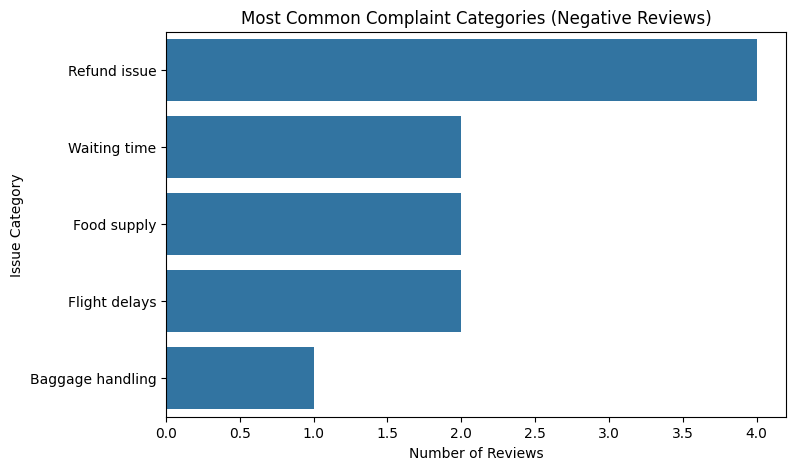

In [37]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
sns.countplot(
    y="issue",
    data=negative_reviews,
    order=negative_reviews["issue"].value_counts().index
)
plt.title("Most Common Complaint Categories (Negative Reviews)")
plt.xlabel("Number of Reviews")
plt.ylabel("Issue Category")
plt.show()


In [34]:
neg_reviews = df_csat[df_csat["csat_label"] == "Low"].copy()
neg_reviews.head()

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc
8,always fly ba total shamble book manchester lo...,0.459759,0.068046,0.651259,0.380545,Low,1
13,flight leave time arrive half hour early sched...,0.198142,0.121218,0.553780,0.246193,Low,1
22,flight fine term comfort punctuality service f...,0.016454,0.265001,0.619833,0.211694,Low,1
24,go fly frankfurt glasgow london flight london ...,0.208199,0.103511,0.574240,0.250001,Low,1
35,fly ba year read review preparation needless s...,0.118769,0.147526,0.528716,0.209386,Low,1


In [33]:
# Intalling bertopic library
!pip install bertopic

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.7/154.7 kB 5.8 MB/s eta 0:00:00


In [35]:
from bertopic import BERTopic

documents = neg_reviews['lemma_review'].tolist()

topic_model = BERTopic(language="english", verbose=True)
topics, probs = topic_model.fit_transform(documents)

/usr/local/lib/python3.12/dist-packages/hdbscan/robust_single_linkage_.py:175: SyntaxWarning: invalid escape sequence '\{'
  $max \{ core_k(a), core_k(b), 1/\alpha d(a,b) \}$.
2025-12-30 18:24:58,033 - BERTopic - Embedding - Transforming documents to embeddings.


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/1 [00:00<?, ?it/s]

2025-12-30 18:25:08,035 - BERTopic - Embedding - Completed ✓
2025-12-30 18:25:08,042 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2025-12-30 18:25:27,937 - BERTopic - Dimensionality - Completed ✓
2025-12-30 18:25:27,940 - BERTopic - Cluster - Start clustering the reduced embeddings
2025-12-30 18:25:27,962 - BERTopic - Cluster - Completed ✓
2025-12-30 18:25:27,972 - BERTopic - Representation - Fine-tuning topics using representation models.
2025-12-30 18:25:28,014 - BERTopic - Representation - Completed ✓


In [36]:
neg_reviews['topic'] = topics
neg_reviews.head()

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc,topic
8,always fly ba total shamble book manchester lo...,0.459759,0.068046,0.651259,0.380545,Low,1,-1
13,flight leave time arrive half hour early sched...,0.198142,0.121218,0.553780,0.246193,Low,1,-1
22,flight fine term comfort punctuality service f...,0.016454,0.265001,0.619833,0.211694,Low,1,-1
24,go fly frankfurt glasgow london flight london ...,0.208199,0.103511,0.574240,0.250001,Low,1,-1
35,fly ba year read review preparation needless s...,0.118769,0.147526,0.528716,0.209386,Low,1,-1


In [38]:
topic_info = topic_model.get_topic_info()
topic_info.head(10)

,Topic,Count,Name,Representation,Representative_Docs
0,-1,11,-1_flight_british_london_ba,"[flight, british, london, ba, airways, hour, t...",[go fly frankfurt glasgow london flight london...


In [41]:
topic_model.get_topic(-1)


[('flight', np.float64(0.15721825444567758)),
 ('british', np.float64(0.06553796243378232)),
 ('london', np.float64(0.06553796243378232)),
 ('ba', np.float64(0.062166086590417675)),
 ('airways', np.float64(0.05872142431225666)),
 ('hour', np.float64(0.05872142431225666)),
 ('tell', np.float64(0.044083290891150054)),
 ('get', np.float64(0.04016413340868655)),
 ('day', np.float64(0.04016413340868655)),
 ('hotel', np.float64(0.04016413340868655))]

In [43]:
topic_labels = {
    0: "Flight Delays",
    1: "Staff Behavior",
    2: "Food Quality",
    3: "Seating Comfort",
    4: "Baggage Handling",
    5: "Refund and Pricing Issues"
}

neg_reviews["issue"] = neg_reviews["topic"].map(topic_labels)
neg_reviews[["lemma_review", "issue"]].head()


,lemma_review,issue
8,always fly ba total shamble book manchester lo...,NaN
13,flight leave time arrive half hour early sched...,NaN
22,flight fine term comfort punctuality service f...,NaN
24,go fly frankfurt glasgow london flight london ...,NaN
35,fly ba year read review preparation needless s...,NaN


# Cloud Deployment and Visualization **Dashboard**

I am using Huggingface spaces and Gradio UI for deploying my model

In [3]:
# Importing basic libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
# Loading CSAT dataset
path = '/content/drive/MyDrive/Colab Notebooks/british_airways_with_csat.csv'
csat_df = pd.read_csv(path)
csat_df.head()

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc
0,ba jan appreciate unprofessional attitude pilo...,0.706294,0.646868,0.628529,0.672913,High,0
1,great experience could check online two separa...,0.579247,0.968886,0.733520,0.726993,High,0
2,excited fly ba travel long haul yrs travel aus...,0.130567,0.846605,0.685058,0.456277,Neutral,2
3,want warn everyone bad customer service experi...,0.531010,0.929576,0.642107,0.672799,High,0
4,pay business class travel cairo london heathro...,0.888548,0.088334,0.037949,0.478364,Neutral,2


In [8]:
# Filtering negative reviews based on csat label as low
neg_revs_df = csat_df[csat_df["csat_label"] == "Low"].copy()
neg_revs_df.head()

,lemma_review,score_bert_norm,score_vader_norm,score_tb_norm,ensemble_score,csat_label,csat_enc
8,always fly ba total shamble book manchester lo...,0.459759,0.068046,0.651259,0.380545,Low,1
13,flight leave time arrive half hour early sched...,0.198142,0.121218,0.553780,0.246193,Low,1
22,flight fine term comfort punctuality service f...,0.016454,0.265001,0.619833,0.211694,Low,1
24,go fly frankfurt glasgow london flight london ...,0.208199,0.103511,0.574240,0.250001,Low,1
35,fly ba year read review preparation needless s...,0.118769,0.147526,0.528716,0.209386,Low,1


In [10]:
texts = neg_revs_df['lemma_review'].astype(str).tolist()
texts

['always fly ba total shamble book manchester london madrid ba first leg iberia nd try wherever possible avoid ba however manchester london late however run ib flight get gate boarding start group go board gate sound alarm ba remove ib flight ba flight hour later ba reissue ticket ib could put back flight hour waste ba ’s total incompetence airline total disgrace crew nice typical ba crew oh fabulous need nice pay passenger club europe cramp terrible food',
 'flight leave time arrive half hour early schedule thank strong tail wind flight full catering load economy passenger heathrow half hour small bottle water small packet corn snack nothing available even buy eat bad lowcost carrier experience sense one light panel overhead seat towards back plan break loose hang unfortunate passenger head whole flight poor maintenance cabin would choose another airline route future one competitor offer full meal service route even economy cabin',
 'flight fine term comfort punctuality service feel s

In [12]:
#Downloasing punkt and stopwords
import nltk

nltk.download("punkt", quiet=True)
nltk.download("stopwords", quiet=True)
nltk.download('punkt_tab', quiet=True)

True

In [13]:
# Text preprocessing
import re
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

nltk.download("punkt")
nltk.download("stopwords")

stop_words = set(stopwords.words("english"))

def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^a-z\s]", "", text)
    tokens = word_tokenize(text)
    tokens = [w for w in tokens if w not in stop_words and len(w) > 2]
    return tokens

processed_texts = [preprocess(text) for text in texts]

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [1]:
# Installing required modules
!pip install gensim nltk gradio joblib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.9/27.9 MB 19.8 MB/s eta 0:00:00


In [17]:
# Training LDA Model

from gensim import corpora
from gensim.models import LdaModel

dictionary = corpora.Dictionary(processed_texts)
corpus = [dictionary.doc2bow(text) for text in processed_texts]

lda_model = LdaModel(
    corpus=corpus,
    id2word=dictionary,
    num_topics=5,
    passes=10,
    random_state=42
)

In [19]:
# Viewing Topics
lda_model.print_topics()

[(0,
  '0.044*"flight" + 0.023*"british" + 0.020*"airways" + 0.013*"tell" + 0.013*"hour" + 0.010*"day" + 0.010*"help" + 0.010*"hotel" + 0.010*"claim" + 0.010*"connect"'),
 (1,
  '0.003*"flight" + 0.003*"british" + 0.002*"airways" + 0.002*"hotel" + 0.002*"hour" + 0.002*"next" + 0.002*"receive" + 0.002*"day" + 0.002*"tell" + 0.002*"vegas"'),
 (2,
  '0.048*"flight" + 0.025*"london" + 0.015*"cancel" + 0.013*"total" + 0.013*"get" + 0.013*"hour" + 0.010*"back" + 0.010*"fly" + 0.009*"never" + 0.009*"luggage"'),
 (3,
  '0.022*"breakfast" + 0.015*"flight" + 0.008*"could" + 0.008*"prior" + 0.008*"chicken" + 0.008*"lhr" + 0.008*"book" + 0.008*"low" + 0.008*"business" + 0.008*"service"'),
 (4,
  '0.018*"flight" + 0.010*"even" + 0.010*"airline" + 0.010*"though" + 0.010*"trip" + 0.010*"good" + 0.010*"time" + 0.010*"economy" + 0.010*"crew" + 0.009*"find"')]

In [20]:
# Defining issue and Recommendation mapping
topic_issue_map = {
    1: "Flight delays",
    4: "Poor customer service",
    2: "Baggage handling issues",
    0: "Refund issues",
    3: "Food quality complaints"
}

issue_recommendation_map = {
    "Flight delays": "Improve schedule planning and real-time communication.",
    "Poor customer service": "Provide additional staff training and faster response channels.",
    "Baggage handling issues": "Enhance baggage tracking and handling procedures.",
    "Refund issues": "Improve automatic refund system as well as enhance customer experience. ",
    "Food quality complaints": "Review catering vendors and menu quality."
}

In [21]:
# Creating Inference Function
def predict_issue_and_recommendation(user_text):
    tokens = preprocess(user_text)
    bow = dictionary.doc2bow(tokens)

    topic_probs = lda_model.get_document_topics(bow)
    dominant_topic = max(topic_probs, key=lambda x: x[1])[0]

    issue = topic_issue_map.get(dominant_topic, "General issue")
    recommendation = issue_recommendation_map.get(
        issue, "Further investigation required."
    )

    return issue, recommendation

In [29]:
# Just testing function
u_text = input("Enter your review: ")
predict_issue_and_recommendation(u_text)

Enter your review: Payment system fails frequently


('Refund issues',
 'Improve automatic refund system as well as enhance customer experience. ')

In [30]:
# Saving required models and functions to pickle files
import joblib

joblib.dump(lda_model, "lda_model.pkl")
joblib.dump(dictionary, "dictionary.pkl")
joblib.dump(topic_issue_map, "topic_issue_map.pkl")
joblib.dump(issue_recommendation_map, "issue_recommendation_map.pkl")

['issue_recommendation_map.pkl']

In [37]:
# Creating Gradio UI
import gradio as gr

def gradio_app(user_input):
    issue, recommendation = predict_issue_and_recommendation(user_input)
    return issue, recommendation

interface = gr.Interface(
    fn=gradio_app,
    inputs=gr.Textbox(lines=4, placeholder="Enter your feedback here"),
    outputs=[
        gr.Textbox(label="Identified Issue"),
        gr.Textbox(label="Recommended Action", lines=10)
    ],
    title="Customer Feedback Issue Analyzer",
    description="Enter customer feedback to identify issues and recommendations"
)

interface.launch(share=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

In [38]:
interface.close()

Closing server running on port: 7860
